# 01 — Exploratory Data Analysis
UCI Diabetes 130-US Hospitals (1999–2008). **EDA only — no training here.**
Run top-to-bottom (Restart & Run All).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import NUMERIC_COLS, RANDOM_STATE
from src.data_loader import load_and_clean, load_raw, make_target

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
print("RANDOM_STATE =", RANDOM_STATE)

RANDOM_STATE = 42


## 1. Raw data overview

In [2]:
df_raw = load_raw()
print(f"Raw shape: {df_raw.shape}")
df_raw.head(3)

Raw shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


## 2. Target distribution — class imbalance
`readmitted`: `<30` (positive), `>30`, `NO`. The positive class is ~11%.

clean_data: 101,766 -> 99,340 rows (2,426 removed)


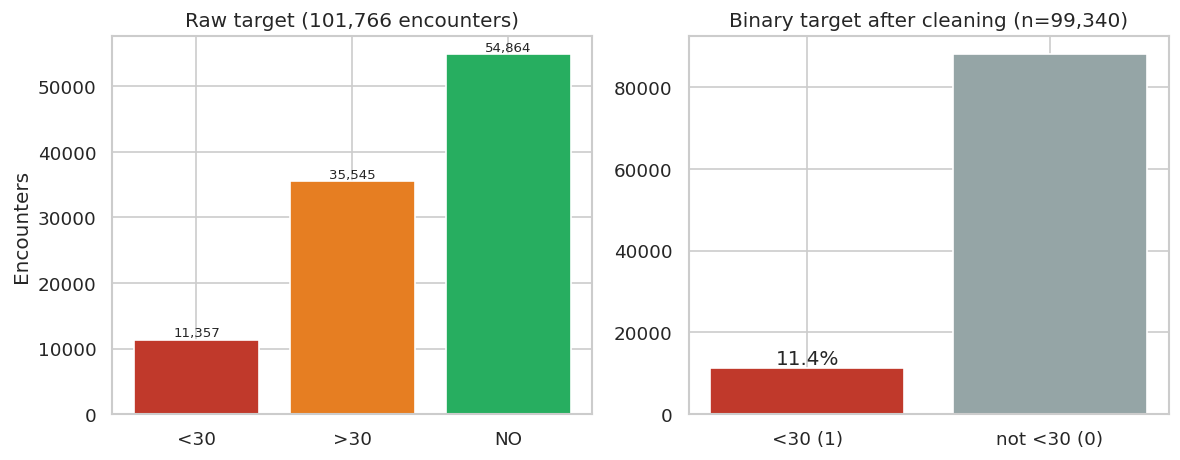

In [3]:
df_clean = load_and_clean()
y_binary = make_target(df_clean)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
order = ["<30", ">30", "NO"]
counts = df_raw["readmitted"].value_counts().reindex(order)
axes[0].bar(order, counts, color=["#c0392b", "#e67e22", "#27ae60"])
axes[0].set_title("Raw target (101,766 encounters)")
axes[0].set_ylabel("Encounters")
for i, v in enumerate(counts):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)

axes[1].bar(["<30 (1)", "not <30 (0)"],
            [y_binary.sum(), len(y_binary) - y_binary.sum()],
            color=["#c0392b", "#95a5a6"])
axes[1].set_title(f"Binary target after cleaning (n={len(y_binary):,})")
axes[1].text(0, y_binary.sum(), f"{y_binary.mean():.1%}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 3. Missing values (`?` encoded as NaN on load)

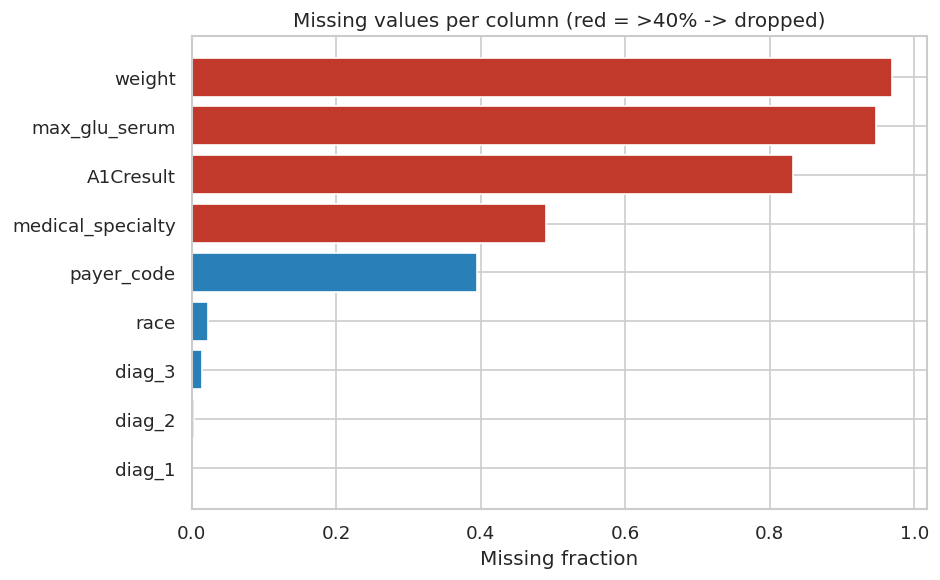

Columns with >40% missing: ['weight', 'max_glu_serum', 'A1Cresult', 'medical_specialty']


In [4]:
missing_pct = df_raw.replace("?", np.nan).isna().mean().sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#c0392b" if v > 0.4 else "#2980b9" for v in missing_pct]
ax.barh(missing_pct.index[::-1], missing_pct.values[::-1], color=colors[::-1])
ax.set_xlabel("Missing fraction")
ax.set_title("Missing values per column (red = >40% -> dropped)")
plt.tight_layout(); plt.show()
print("Columns with >40% missing:", list(missing_pct[missing_pct > 0.4].index))

## 4. Encounters per patient — why GroupSplit is mandatory
The same patient appears up to 40 times. A random split would place correlated
encounters of one patient in both train and test (silent leakage).

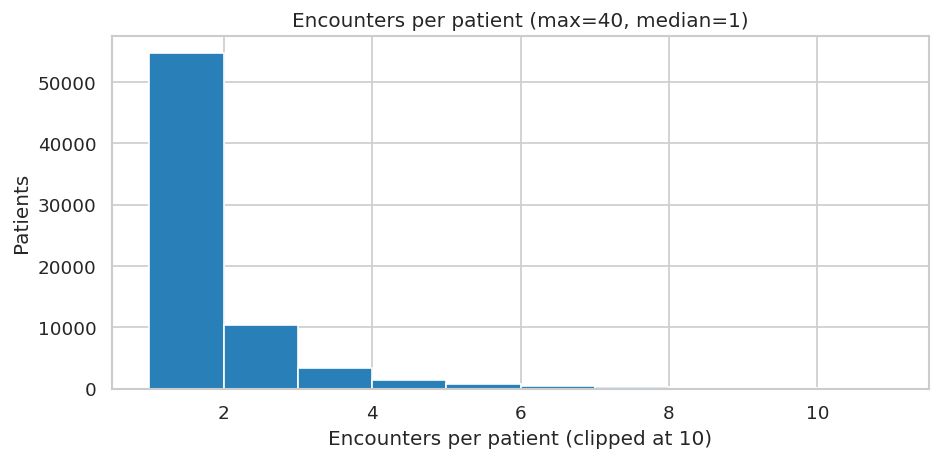

Patients with >1 encounter: 16,773 (23.5%)


In [5]:
enc_per_patient = df_raw.groupby("patient_nbr").size()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(enc_per_patient.clip(upper=10), bins=range(1, 12),
        color="#2980b9", edgecolor="white")
ax.set_xlabel("Encounters per patient (clipped at 10)")
ax.set_ylabel("Patients")
ax.set_title(f"Encounters per patient (max={enc_per_patient.max()}, "
             f"median={enc_per_patient.median():.0f})")
plt.tight_layout(); plt.show()
print(f"Patients with >1 encounter: {(enc_per_patient > 1).sum():,} "
      f"({(enc_per_patient > 1).mean():.1%})")

## 5. Key numeric features

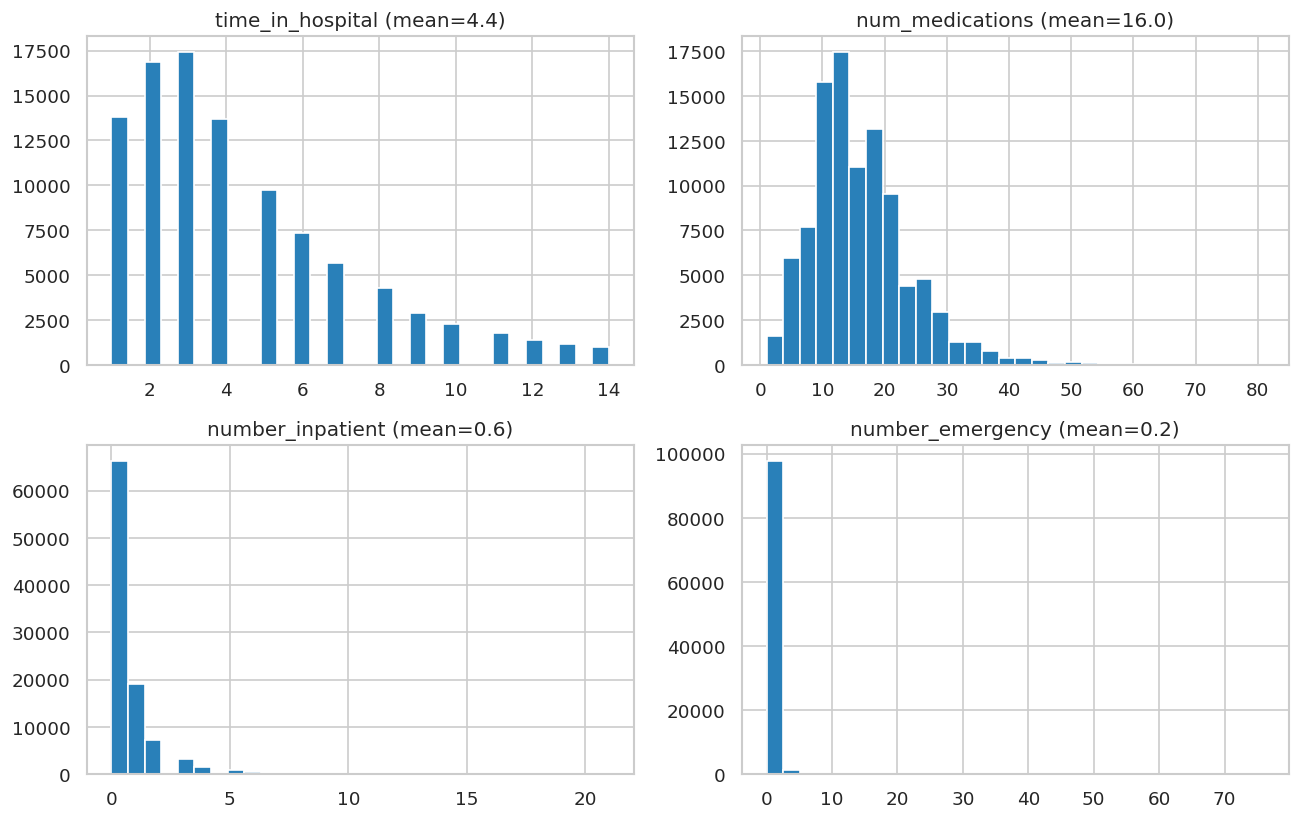

In [6]:
key_numeric = ["time_in_hospital", "num_medications", "number_inpatient", "number_emergency"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), key_numeric):
    df_clean[col].hist(ax=ax, bins=30, color="#2980b9", edgecolor="white")
    ax.set_title(f"{col} (mean={df_clean[col].mean():.1f})")
plt.tight_layout(); plt.show()

## 6. Demographics: age & race

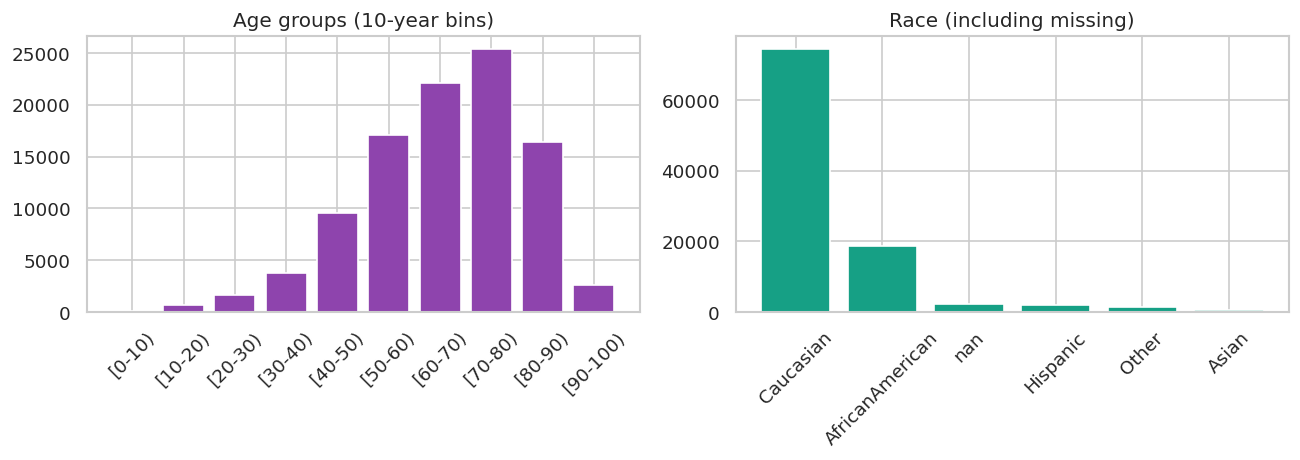

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
age_order = sorted(df_clean["age"].unique())
axes[0].bar(age_order, df_clean["age"].value_counts().reindex(age_order),
            color="#8e44ad", edgecolor="white")
axes[0].set_title("Age groups (10-year bins)")
axes[0].tick_params(axis="x", rotation=45)

race_counts = df_clean["race"].value_counts(dropna=False)
axes[1].bar(race_counts.index.astype(str), race_counts.values,
            color="#16a085", edgecolor="white")
axes[1].set_title("Race (including missing)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 7. Cleaning summary & acceptance check

In [8]:
n_rows = len(df_clean)
n_patients = df_clean["patient_nbr"].nunique()
pos_rate = y_binary.mean()

print(f"Rows after cleaning  : {n_rows:,}  (all encounters kept)")
print(f"Unique patients      : {n_patients:,}  (spec range 69,000-72,000)")
print(f"Positive rate (<30)  : {pos_rate:.2%}  (spec range 10-12%)")
print()
print(f"[{'PASS' if 0.10 <= pos_rate <= 0.12 else 'FAIL'}] positive rate")
print(f"[{'PASS' if 69000 <= n_patients <= 72000 else 'FAIL'}] unique patients")
print()
print("NOTE: all encounters per patient are kept; the spec's row-count range")
print("      (69k-72k) matches the UNIQUE PATIENT count. Leakage is prevented")
print("      by GroupShuffleSplit on patient_nbr (see src/train.py).")

Rows after cleaning  : 99,340  (all encounters kept)
Unique patients      : 69,987  (spec range 69,000-72,000)
Positive rate (<30)  : 11.39%  (spec range 10-12%)

[PASS] positive rate
[PASS] unique patients

NOTE: all encounters per patient are kept; the spec's row-count range
      (69k-72k) matches the UNIQUE PATIENT count. Leakage is prevented
      by GroupShuffleSplit on patient_nbr (see src/train.py).
